In [1]:
# sns.pairplot(df_clean[cols])

In [2]:
import pandas as pd
df=pd.read_csv("smartcart_customers.csv")
df.isna().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
##DataPreprocessing 
#handling missing values
df["Income"]=df["Income"].fillna(df["Income"].median())

## feature Engineering

In [5]:
df["Age"]=2026-df["Year_Birth"].copy()
df["Dt_Customer"]=pd.to_datetime(df["Dt_Customer"],dayfirst=True)
ref_date=df["Dt_Customer"].max()
df["Customer_Tenur_Days"]=(ref_date-df["Dt_Customer"]).dt.days
ref_date

Timestamp('2014-06-29 00:00:00')

In [6]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenur_Days'],
      dtype='str')

In [7]:
#spending
spend_data=['MntWines','MntFruits','MntMeatProducts', 'MntFishProducts', 'MntSweetProducts','MntGoldProds']
sum=0
for data in spend_data:
    sum+=df[data]
    if(data=='MntGoldProds'):
        df["Total_Spending"]=sum
        sum=0
        

In [8]:
#total Childeren
df["Total_Childs"]=df["Kidhome"]+df["Teenhome"]

In [9]:
df["Total_Childs"]

0       0
1       2
2       0
3       1
4       1
       ..
2235    1
2236    3
2237    0
2238    1
2239    2
Name: Total_Childs, Length: 2240, dtype: int64

In [10]:
df.drop("ID",axis=1)

,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenur_Days,Total_Spending,Total_Childs
0,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,...,8,10,4,7,0,1,69,663,1617,0
1,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,...,1,1,2,5,0,0,72,113,27,2
2,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,...,8,2,10,4,0,0,61,312,776,0
3,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,...,2,0,4,6,0,0,42,139,53,1
4,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,...,5,3,6,5,0,0,45,161,422,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,1967,Graduation,Married,61223.0,0,1,2013-06-13,46,709,43,...,9,3,4,5,0,0,59,381,1341,1
2236,1946,PhD,Together,64014.0,2,1,2014-06-10,56,406,0,...,8,2,5,7,0,0,80,19,444,3
2237,1981,Graduation,Divorced,56981.0,0,0,2014-01-25,91,908,48,...,2,3,13,6,0,0,45,155,1241,0
2238,1956,Master,Together,69245.0,0,1,2014-01-24,8,428,30,...,6,5,10,3,0,0,70,156,843,1


In [11]:
# we will divide this into three categoreis 1.underGraduate2.Graduate3,Post Graduate
df["Education"]=df["Education"].replace({
    "Basic":"UnderGraduate","2n Cycle":"UnderGraduate",
    "Graduation":"Graduate",
    "Master":"PostGraduate","PhD":"PostGraduate"   
})

In [12]:
df["Education"].value_counts()

Education
Graduate         1127
PostGraduate      856
UnderGraduate     257
Name: count, dtype: int64

In [13]:
#Martial Status
df["Marital_Status"].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [14]:
df["Live_Together"]=df["Marital_Status"].replace({
    "Married":"Partner","Together":"Partner",
    "Single":"Alone","Divorced":"Alone","Widow":"Alone","Absurd":"Alone","YOLO":"Alone" 
})

In [15]:
df["Live_Together"].value_counts()

Live_Together
Partner    1444
Alone       796
Name: count, dtype: int64

In [16]:
#droping Unneccasary columns
# df_clean.columns

In [17]:
df_clean=df.drop(['ID', 'Year_Birth','Marital_Status','Kidhome','Teenhome','MntWines', 'MntFruits','MntMeatProducts', 'MntFishProducts', 'MntSweetProducts','MntGoldProds','Dt_Customer'],axis=1)

In [18]:
df_clean.shape
cols=['Education', 'Income', 'Recency', 'NumDealsPurchases','NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases','NumWebVisitsMonth', 'Complain', 'Response', 'Age','Customer_Tenur_Days', 'Total_Spending', 'Total_Childs','Live_Together']

In [19]:
#remove the outliers
print(len(df_clean))

2240


In [20]:
df_clean=df_clean[(df_clean["Age"]<90)]
df_clean=df_clean[(df_clean["Income"]<600000)]
print(len(df_clean))

2236


<Axes: >

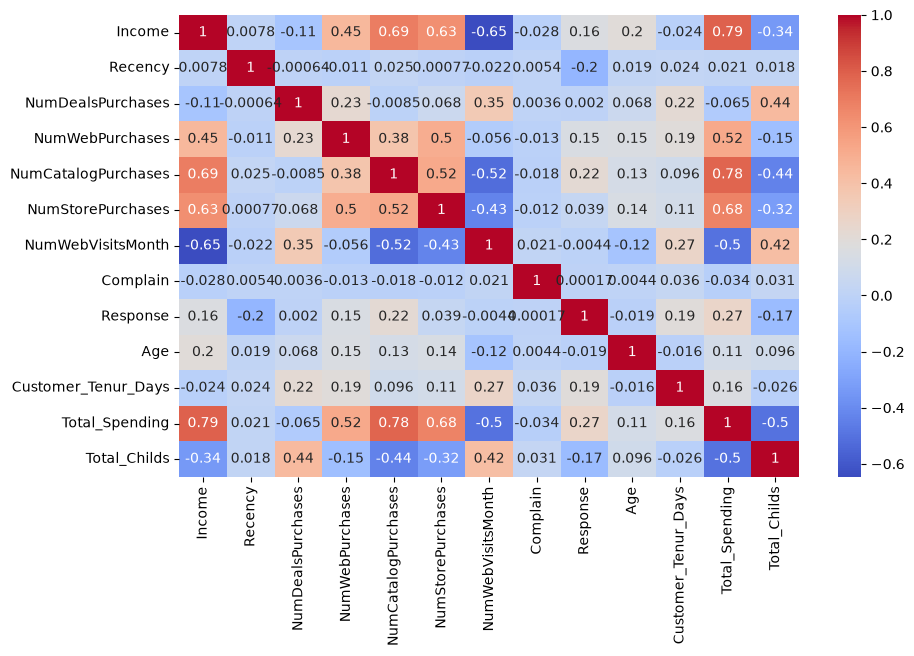

In [21]:
#Correlation
corr=df_clean.corr(numeric_only=True)
plt.figure(figsize=(10,6))
sns.heatmap(corr,
           annot=True,
           cmap="coolwarm")

In [22]:
df_clean.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenur_Days,Total_Spending,Total_Childs,Live_Together
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,PostGraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


In [23]:
#Encoding
from sklearn.preprocessing import OneHotEncoder
ohe=OneHotEncoder()
cat_col=["Education","Live_Together"]
enc_cols=ohe.fit_transform(df_clean[cat_col])
enc_df=pd.DataFrame(enc_cols.toarray(),columns=ohe.get_feature_names_out(cat_col),index=df_clean.index)

In [24]:
df_encoded=pd.concat([df_clean.drop(columns=cat_col),enc_df],axis=1)

In [25]:
##Scaling
from sklearn.preprocessing import StandardScaler
x=df_encoded
scaler=StandardScaler()
x_s=scaler.fit_transform(x)

In [26]:
#Visulizing our data
from sklearn.decomposition import PCA
pca=PCA(n_components=5)
x_pca=pca.fit_transform(x_s)

In [27]:
pca.explained_variance_ratio_

array([0.23163158, 0.11385454, 0.10405815, 0.09912103, 0.07729999])

Text(0.5, 0.92, 'pca1 vs pca2 vs pca3')

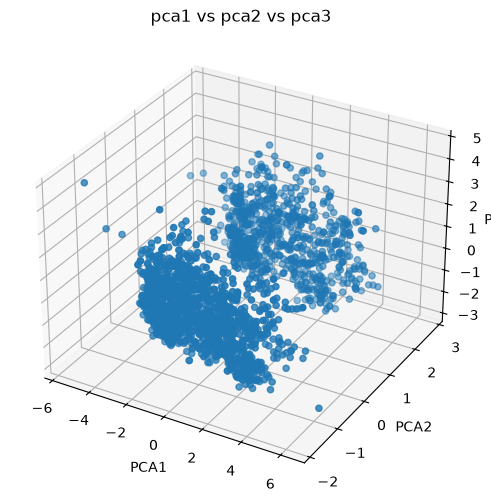

In [28]:
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2])
ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("pca1 vs pca2 vs pca3")

In [29]:
pca.explained_variance_ratio_

array([0.23163158, 0.11385454, 0.10405815, 0.09912103, 0.07729999])

In [30]:
#Analyse k value
from sklearn.cluster import KMeans
wcss=[]
for k in range(1,21):
    km=KMeans(n_clusters=k)
    km.fit_predict(x_pca)
    wcss.append(km.inertia_)
    

In [31]:
from kneed import KneeLocator
knee=KneeLocator(range(1,21),wcss,curve="convex",direction="decreasing")
k=knee.knee
print(k)

7


In [32]:
from sklearn.metrics import silhouette_score
ss=[]
for k in range(2,21):
    model=KMeans(n_clusters=k)
    labels=model.fit_predict(x_pca)
    score=silhouette_score(x_pca,labels)
    ss.append(score)

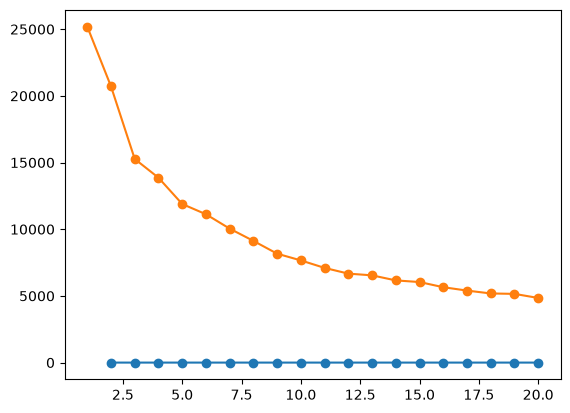

In [33]:
plt.plot(range(2,21),ss,marker="o")
plt.plot(range(1,21),wcss,marker="o")

Text(0.5, 0.92, 'pca1 vs pca2 vs pca3')

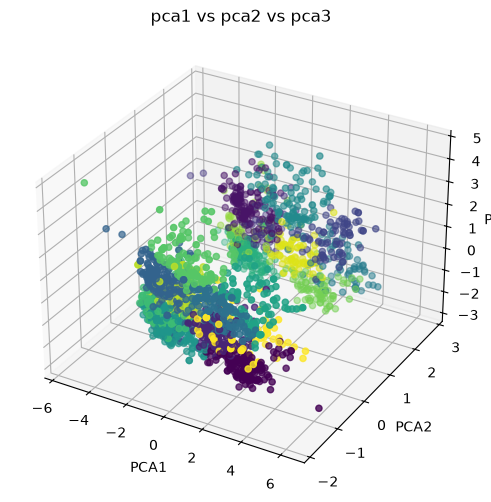

In [34]:
km=KMeans(n_clusters=4)
lables=km.fit_predict(x_pca)
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2],c=labels)
ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("pca1 vs pca2 vs pca3")

Text(0.5, 0.92, 'pca1 vs pca2 vs pca3')

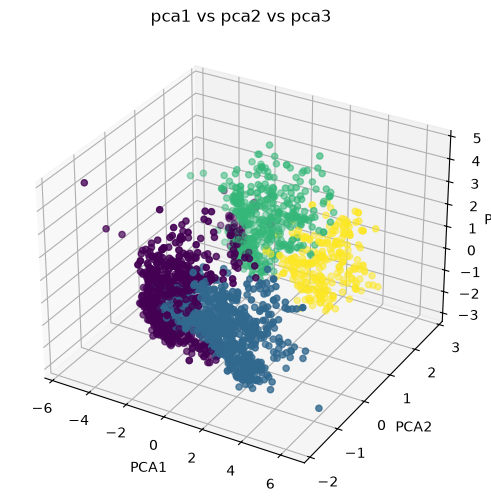

In [35]:
from sklearn.cluster import AgglomerativeClustering
model=AgglomerativeClustering(n_clusters=4)
labels=model.fit_predict(x_pca)
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2],c=labels)
ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("pca1 vs pca2 vs pca3")

In [36]:
#Charaterition of the cluster
df_clean["Clusters"]=labels

<Axes: xlabel='Clusters', ylabel='count'>

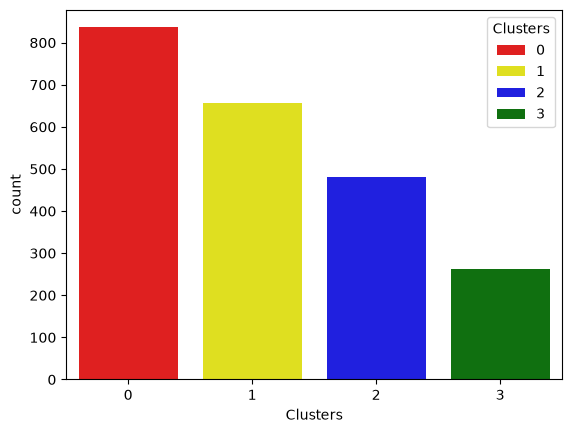

In [38]:
pal=["red","yellow","blue","green"]
sns.countplot(x=df_clean["Clusters"],palette=pal,hue=df_clean["Clusters"])

<Axes: xlabel='Total_Spending', ylabel='Income'>

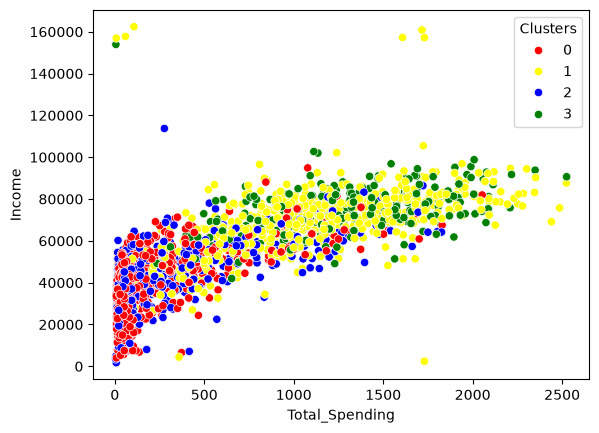

In [43]:
sns.scatterplot(x=df_clean["Total_Spending"],y=df_clean["Income"],hue=df_clean["Clusters"],palette=pal)

In [46]:
c_s=df_clean.groupby("Clusters").mean(numeric_only=True)
print(c_s)

                Income    Recency  NumDealsPurchases  NumWebPurchases  \
Clusters                                                                
0         37857.309809  49.113636           2.392344         2.740431   
1         67853.491616  48.617378           2.291159         5.608232   
2         42741.803942  49.070539           2.807054         3.852697   
3         74060.664122  50.458015           1.316794         5.011450   

          NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
Clusters                                                                        
0                    0.912679           3.877990           6.398325  0.008373   
1                    4.689024           8.033537           4.059451  0.009146   
2                    1.497925           4.680498           6.400415  0.012448   
3                    5.320611           8.362595           3.038168  0.003817   

          Response        Age  Customer_Tenur_Days  Total_Spending  \
Clus